In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import warnings 
warnings.filterwarnings('ignore')

In [3]:
sns.set_style('whitegrid') #set the overall aesthetic theme 
plt.rcParams['figure.figsize']=(10,6) #set the default width and height for all subsequent charts and plots 


In [5]:
df = pd.read_csv('consumer_shopping_behavior_survey.csv')
df.head()

,Response_ID,Timestamp,Age,Gender,Occupation_Status,Country_Region,Monthly_Income_Range,Shop_Most_Where,Online_Shopping_Frequency,Preferred_Platform,...,Return_Frequency,Avg_Monthly_Spend_NonEssentials,Preferred_Payment_Method,Uses_BNPL_Installments,Online_Shopping_Satisfaction_Score,Trust_In_Online_Reviews_Score,Regret_After_Purchase_Frequency,Reason_Prefer_Online,Reason_Prefer_InStore,Best_Shopping_Mode
0,1,01/08/2026 12:30:25,20,Male,NaN,Philippines,"Under $1,000",Equal mix,Often,Physical stores,...,Never,Under $50,Digital wallet,"Yes, occasionally",6.0,7.0,2.0,More variety,No delivery wait,Online
1,2,21/06/2026 13:52:02,24,Male,Employed part-time,Brazil,"Under $1,000",In-store only,Often,Local e-commerce,...,Often,Under $50,Digital wallet,"No, never",5.0,8.0,3.0,NaN,Try product before buying,Offline
2,3,15/08/2026 04:24:18,22,Female,Student,India,"Under $1,000",Equal mix,Always,Local e-commerce,...,Sometimes,$150-300,Credit Card,"No, never",7.0,6.0,2.0,Better prices,Trust,Online
3,4,23/06/2026 21:24:21,20,Male,Student,NaN,"Under $1,000",In-store only,Occasionally,Brand websites,...,Never,Under $50,Debit Card,"No, never",8.0,7.0,3.0,Better prices,Try product before buying,Equal / both
4,5,20/08/2026 16:24:47,41,Male,Employed full-time,United States,"$1,000-3,000",Equal mix,Occasionally,NaN,...,Sometimes,$50-150,Debit Card,"No, never",6.0,8.0,2.0,Convenience,Trust,Equal / both


In [6]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode'],
      dtype='str')

In [7]:
df.shape

(500, 30)

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 30 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   Response_ID                         500 non-null    int64  
 1   Timestamp                           500 non-null    str    
 2   Age                                 478 non-null    str    
 3   Gender                              484 non-null    str    
 4   Occupation_Status                   479 non-null    str    
 5   Country_Region                      480 non-null    str    
 6   Monthly_Income_Range                479 non-null    str    
 7   Shop_Most_Where                     484 non-null    str    
 8   Online_Shopping_Frequency           481 non-null    str    
 9   Preferred_Platform                  486 non-null    str    
 10  Primary_Device                      492 non-null    str    
 11  Top_Spending_Category               476 non-null    str 

In [9]:
df.isna().sum()

Response_ID                            0
Timestamp                              0
Age                                   22
Gender                                16
Occupation_Status                     21
Country_Region                        20
Monthly_Income_Range                  21
Shop_Most_Where                       16
Online_Shopping_Frequency             19
Preferred_Platform                    14
Primary_Device                         8
Top_Spending_Category                 24
Review_Influence_Score                15
Social_Ads_Influence_Score            21
Price_Comparison_Frequency            26
Discount_Importance_Score             23
Follows_Brands_On_Social              11
Likely_To_Buy_After_Ad_Score          25
Makes_Shopping_List                   24
Impulse_Purchase_Frequency            16
Return_Frequency                      17
Avg_Monthly_Spend_NonEssentials       20
Preferred_Payment_Method              15
Uses_BNPL_Installments                12
Online_Shopping_

In [10]:
df.duplicated().sum()

np.int64(0)

Change the values in the Age column into numbers and replace unknown or missing values with errors
Transform the text in the Timestamp column into python datetime objects 

In [12]:
df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Timestamp'] = pd.to_datetime(df['Timestamp'], format= "%d/%m/%Y %H:%M:%S")

In [14]:
df[['Age', 'Timestamp']].dtypes

Age                 float64
Timestamp    datetime64[us]
dtype: object

In [15]:
df['Age'].describe()

count    470.000000
mean      25.019149
std        7.515276
min       16.000000
25%       20.000000
50%       22.000000
75%       30.000000
max       50.000000
Name: Age, dtype: float64

In [16]:
df['Reason_Prefer_Online'].value_counts()


Reason_Prefer_Online
More variety      170
Convenience       157
Better prices      81
Not applicable     38
Name: count, dtype: int64

group numeric ages into 5 distinct age categories and save them in a new column called Age_Group

In [18]:
bins = [0, 18, 25, 35, 50, 100]

labels = ['Under 18', '18-25', '26-35', '36-50', '50+']

df['Age_Group'] = pd.cut(df['Age'], bins=bins, labels=labels)

In [19]:
df['Age_Group'].value_counts()

Age_Group
18-25       228
26-35       110
Under 18     78
36-50        54
50+           0
Name: count, dtype: int64

Clean missing data across specific columns and replace empty values with Unknown and verify the result 

In [20]:
cols_to_fill = ['Gender', 'Occupation_Status', 'Country_Region',
 'Shop_Most_Where', 'Preferred_Platform', 'Preferred_Payment_Method']
 


In [21]:
for col in cols_to_fill:
    df[col] = df[col].fillna('Unknown')
    

In [22]:
df[cols_to_fill].isna().sum()

Gender                      0
Occupation_Status           0
Country_Region              0
Shop_Most_Where             0
Preferred_Platform          0
Preferred_Payment_Method    0
dtype: int64

In [23]:
df.columns

Index(['Response_ID', 'Timestamp', 'Age', 'Gender', 'Occupation_Status',
       'Country_Region', 'Monthly_Income_Range', 'Shop_Most_Where',
       'Online_Shopping_Frequency', 'Preferred_Platform', 'Primary_Device',
       'Top_Spending_Category', 'Review_Influence_Score',
       'Social_Ads_Influence_Score', 'Price_Comparison_Frequency',
       'Discount_Importance_Score', 'Follows_Brands_On_Social',
       'Likely_To_Buy_After_Ad_Score', 'Makes_Shopping_List',
       'Impulse_Purchase_Frequency', 'Return_Frequency',
       'Avg_Monthly_Spend_NonEssentials', 'Preferred_Payment_Method',
       'Uses_BNPL_Installments', 'Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode',
       'Age_Group'],
      dtype='str')

Check which rows are completely empty across all last 6 columns and count the total drop offs

In [24]:
last6 = ['Online_Shopping_Satisfaction_Score',
       'Trust_In_Online_Reviews_Score', 'Regret_After_Purchase_Frequency',
       'Reason_Prefer_Online', 'Reason_Prefer_InStore', 'Best_Shopping_Mode']
       

In [ ]:
dropoff = df[last6].isna().all(axis=1) #Checks horizontally across each row 

In [26]:
dropoff.sum()

np.int64(30)

Check dropoff dates 

Filter the Timestamp column to show only the 30 drop off rows found earlier

In [28]:
df.loc[dropoff, 'Timestamp'].dt.date.value_counts().sort_index()


Timestamp
2026-06-20    1
2026-06-22    1
2026-06-24    1
2026-06-29    1
2026-06-30    1
2026-07-02    1
2026-07-03    1
2026-07-05    1
2026-07-06    1
2026-07-07    2
2026-07-09    1
2026-07-10    1
2026-07-16    1
2026-07-24    2
2026-07-27    2
2026-07-28    1
2026-07-30    1
2026-08-02    1
2026-08-03    1
2026-08-15    2
2026-08-16    1
2026-08-17    1
2026-08-18    1
2026-08-19    1
2026-08-21    1
2026-08-24    1
Name: count, dtype: int64

Cross tabulate shopping location vs In-Store reason by building a frequency table comparing where respondentrs shop most against their reason for preferring instore shopping, specifically including missing values

pd.crosstab() groups the rows by Shop_Most_Where and spreads the categories of Reason-Prefer_InStore across the columns 
missing answers appear in their own NaN column instead of being hidden 


In [30]:
pd.crosstab(df['Shop_Most_Where'], df['Reason_Prefer_InStore'], dropna=False)

Reason_Prefer_InStore,No delivery wait,Not applicable,Trust,Try product before buying,NaN
Shop_Most_Where,,,,,
Equal mix,54,42,49,74,29
In-store only,15,10,16,21,9
Online only,43,20,51,46,5
Unknown,7,0,3,4,2


create a summary table called age-summary that calculates average survey scores and counts respondents for each age group.
    split the dataset into separate buckets for each age group  and set observed=True  to only include age categories that actually exist in our data.
    calculate four summary metrics for each group and assign clean names to the resulting column 
    round all calculated averages to 2 decimal places 
    assign this to age_summary 
    


In [31]:
age_summary = df.groupby('Age_Group', observed=True).agg(
    avg_satisfaction=('Online_Shopping_Satisfaction_Score', 'mean'),
    avg_trust=('Trust_In_Online_Reviews_Score', 'mean'),
    avg_regret=('Regret_After_Purchase_Frequency', 'mean'),
    respondents = ('Response_ID', 'count')
).round(2)

In [32]:
age_summary

,avg_satisfaction,avg_trust,avg_regret,respondents
Age_Group,,,,
Under 18,7.25,6.06,2.06,78
18-25,7.04,6.11,2.29,228
26-35,7.17,6.14,2.17,110
36-50,7.02,6.48,1.93,54


In [33]:
top_countries = df['Country_Region'].value_counts().head(8).index

In [34]:
top_countries 

Index(['India', 'United States', 'Brazil', 'Mexico', 'Indonesia', 'Kenya',
       'Egypt', 'Philippines'],
      dtype='str', name='Country_Region')

Filter dataset down to the top 8 countries and compare their average shopping scores 

In [35]:
country_summary = df[df['Country_Region'].isin(top_countries)].groupby('Country_Region', observed=True).agg(
    avg_satisfaction=('Online_Shopping_Satisfaction_Score', 'mean'),
    avg_trust=('Trust_In_Online_Reviews_Score', 'mean'),
    avg_regret=('Regret_After_Purchase_Frequency', 'mean'),
    respondents = ('Response_ID', 'count')
)

country_summary 

,avg_satisfaction,avg_trust,avg_regret,respondents
Country_Region,,,,
Brazil,7.114286,6.812500,2.151515,38
Egypt,6.521739,6.454545,2.045455,25
India,6.779661,5.655738,2.295082,66
Indonesia,7.434783,6.304348,2.181818,26
Kenya,7.240000,5.640000,2.208333,26
Mexico,7.250000,6.151515,2.096774,35
Philippines,7.090909,6.304348,1.826087,23
United States,7.387755,6.466667,2.111111,56


In [ ]:
occupation_summary = df.groupby('Occupation_Status', observed=True).agg(
    avg_impulse=('Impulse_Purchase_Frequency', 'mean'),
    avg_discount_importance=('Discount_Importance_Score', 'mean'),
    bnpl_regular_rate = ('Uses_BNPL_Installments', lambda x: (x=='Yes, regularly').mean()), #lambda function here turns each text answer into true (1) or false(0)

).round(2).sort_values(by='avg_impulse', ascending=False)

In [37]:
occupation_summary 

,avg_impulse,avg_discount_importance,bnpl_regular_rate
Occupation_Status,,,
Employed part-time,2.86,3.94,0.10
Student,2.61,3.80,0.13
Unknown,2.50,3.67,0.05
Employed full-time,2.46,3.90,0.14
Self-employed,2.45,3.78,0.12
Unemployed,2.44,3.47,0.05


In [41]:
pivot_payment = pd.pivot_table(df, index='Shop_Most_Where', columns='Preferred_Payment_Method',
 values='Response_ID', aggfunc='count', fill_value=0)

pivot_payment 

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,34,52,68,88,6
In-store only,10,18,16,24,3
Online only,18,37,40,65,5
Unknown,2,2,5,6,1


pivot_payment.sum(axis=1): adds up all the values across each row 
.div(...., axis=0): divides every cell in a row by that specific rows total and axis=0  aligns the division along the vertical row index 

In [39]:
pivot_payment_pct = pivot_payment.div(pivot_payment.sum(axis=1), axis=0).round(2)

In [40]:
pivot_payment_pct

Preferred_Payment_Method,Cash,Credit Card,Debit Card,Digital wallet,Unknown
Shop_Most_Where,,,,,
Equal mix,0.14,0.21,0.27,0.35,0.02
In-store only,0.14,0.25,0.23,0.34,0.04
Online only,0.11,0.22,0.24,0.39,0.03
Unknown,0.12,0.12,0.31,0.38,0.06


In [45]:
pivot_gender_spend = pd.pivot_table(df, index='Gender', columns='Top_Spending_Category',
 values='Response_ID', aggfunc='count', fill_value=0)
pivot_gender_spend 

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,11,15,64,23,36,21
Male,20,16,98,39,44,25
Prefer not to say,5,5,11,12,9,7
Unknown,0,2,6,2,3,2


In [43]:
pivot_gender_spend_pct = pivot_gender_spend.div(pivot_gender_spend.sum(axis=1), axis=0).round(2)

In [44]:
pivot_gender_spend_pct 

Top_Spending_Category,Beauty & personal care,Books,Clothing,Electronics,Groceries,miscellaneous
Gender,,,,,,
Female,0.06,0.09,0.38,0.14,0.21,0.12
Male,0.08,0.07,0.40,0.16,0.18,0.10
Prefer not to say,0.10,0.10,0.22,0.24,0.18,0.14
Unknown,0.00,0.13,0.40,0.13,0.20,0.13


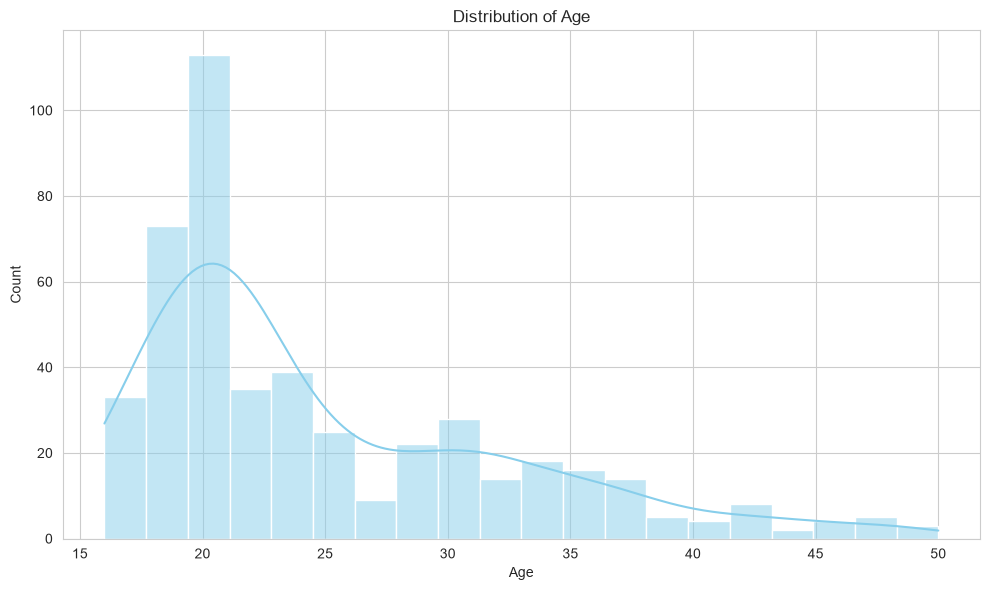

In [47]:
sns.histplot(df['Age'], bins=20, kde=True, color='skyblue')
plt.title('Distribution of Age')
plt.xlabel('Age')
plt.ylabel('Count')
plt.tight_layout()
plt.show()


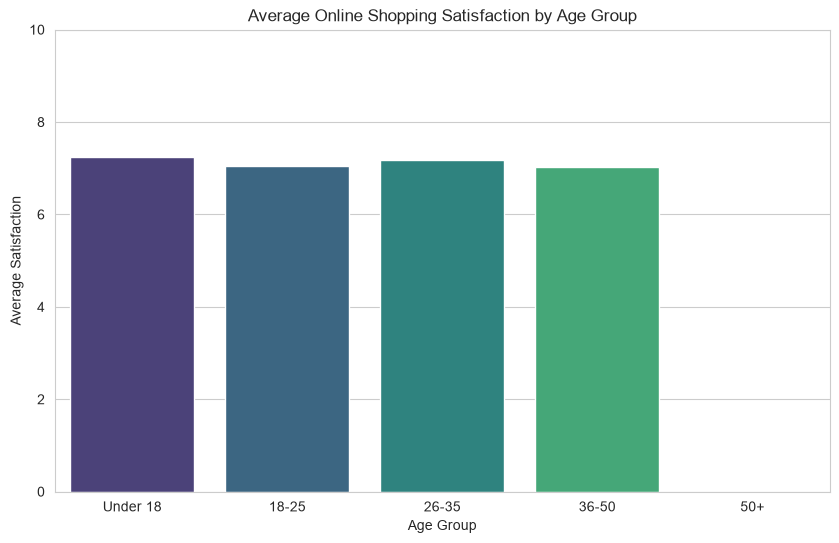

In [ ]:
sns.barplot(x= age_summary.index, y=age_summary['avg_satisfaction'], palette='viridis')#Age_summary table
plt.title('Average Online Shopping Satisfaction by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Satisfaction')
plt.ylim(0, 10)
plt.show()

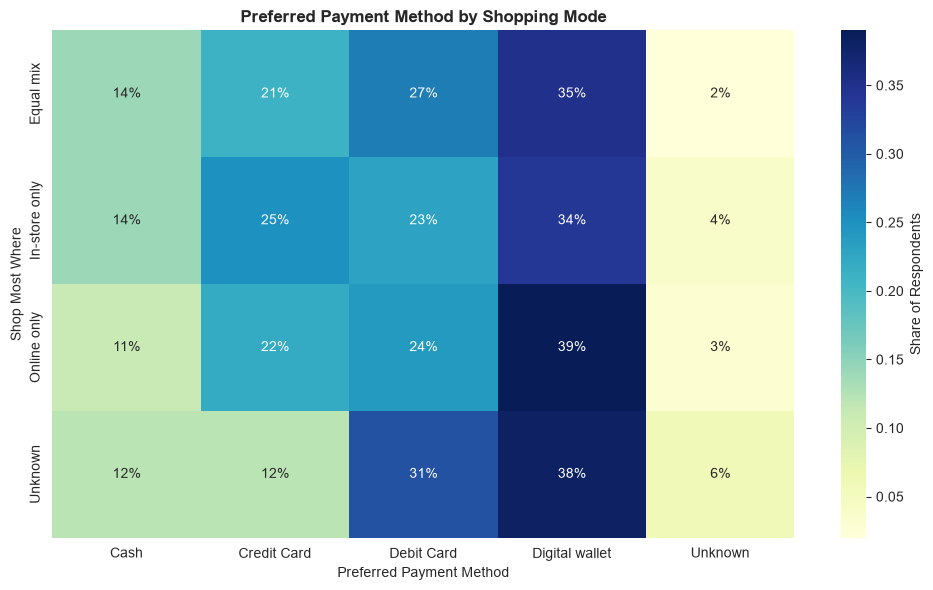

In [49]:
sns.heatmap(pivot_payment_pct, annot=True, fmt='.0%', cmap='YlGnBu', cbar_kws={"label":"Share of Respondents"})
plt.title("Preferred Payment Method by Shopping Mode", fontweight="bold")
plt.xlabel("Preferred Payment Method")
plt.ylabel("Shop Most Where")
plt.tight_layout()
plt.show()

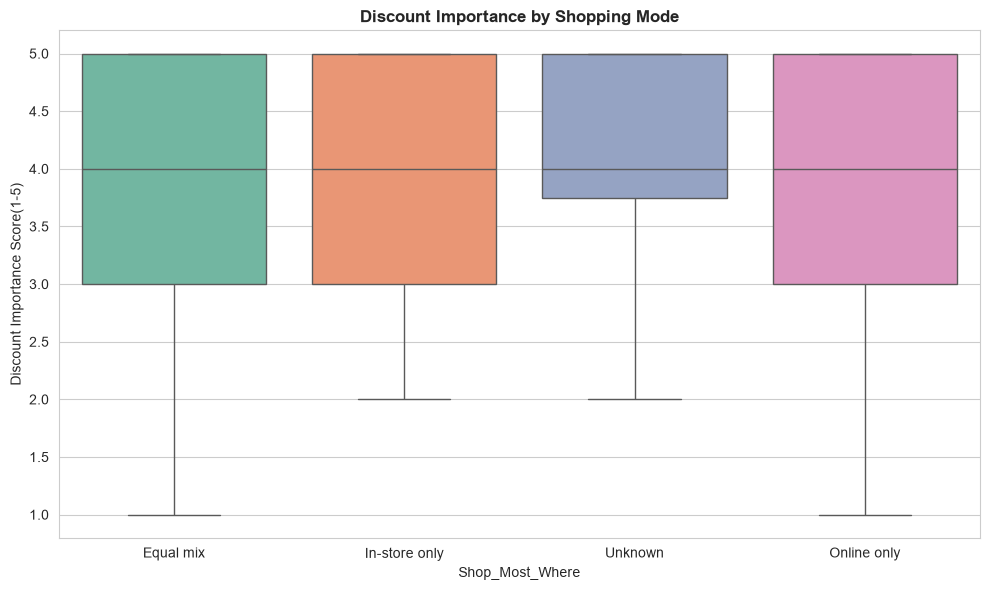

In [51]:
sns.boxplot(x="Shop_Most_Where", y='Discount_Importance_Score', data=df, palette='Set2')
plt.title("Discount Importance by Shopping Mode", fontweight="bold")
plt.xlabel("Shop_Most_Where")
plt.ylabel("Discount Importance Score(1-5)")
plt.tight_layout()
plt.show()